# 02 · Canasta comparable

No se promedian todos los precios de cada ciudad: municipios distintos tienen productos,
marcas, presentaciones y cadenas distintos. Aquí se define una canasta fija y se
comprueba su cobertura.

Decisiones explícitas:

1. **Canal:** solo «Supermercado / Tienda de Autoservicio» (79 % de los registros de
   alimentos). Mercados y centrales de abasto tienen otra lógica de precio y cobertura muy desigual.
2. **Producto normalizado:** un producto + una lista cerrada de presentaciones literalmente
   equivalentes (por ejemplo, arroz súper extra de 900 g, 907 g o 1 kg). Las variantes
   (negro vs. pinto, entero vs. con vísceras) se tratan como productos distintos.
3. **Unidad:** la cantidad se extrae de la presentación y se calcula precio por kg, litro o pieza.
   Las presentaciones ambiguas («800 Ó 880 Gr.») no se usan.
4. **Ventana temporal:** todo el archivo disponible, del 16 al 31 de agosto de 2026
   (12 días con observaciones). Es la ventana completa disponible y no hay datos más
   cercanos a la ENSU de junio.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
PROC = ROOT / "data/processed"
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
from src.exploration import load_data
from src.cleaning import prepare, quality_flags, parse_quantity, CANAL
from src.basket import (CANDIDATOS, select_observations, area_item_prices, coverage_matrix,
                        select_items, brand_option, basket_cost)
prepared = prepare(load_data())
homolog = pd.read_csv(PROC / "homologacion_geografica.csv", dtype={"cd_ensu": str, "cve_mun": str, "cve_ent": str})
display(quality_flags(prepared).to_frame("valor"))
names = CANDIDATOS.set_index("producto_normalizado").nombre

,valor
registros,657602
duplicados_exactos,0
precio_no_valido,0
fecha_invalida,0
coordenadas_faltantes,182
registros_canal_autoservicio,494742


## 1. Candidatos y normalización de unidades

In [2]:
rules = CANDIDATOS.explode("presentaciones").rename(columns={"presentaciones": "presentacion"})
q = rules.presentacion.map(parse_quantity)
rules["cantidad"], rules["unidad_detectada"] = q.str[0], q.str[1]
display(rules[["producto_normalizado", "producto", "presentacion", "cantidad", "unidad_detectada",
               "unidad", "cantidad_canasta"]])
assert (rules.unidad == rules.unidad_detectada).all()
# Ejemplos de presentaciones que NO se normalizan por ambigüedad
for p in ["Paquete 800 Ó 880 Gr.", "Paquete 1 Kg. Ó 1.1 Kg.", "Manojo. Cambray"]:
    print(p, "->", parse_quantity(p))

,producto_normalizado,producto,presentacion,cantidad,unidad_detectada,unidad,cantidad_canasta
0,tortilla_maiz,Tortilla de Maíz,1 Kg. Granel,1.000,kg,kg,1.00
1,huevo_blanco,Huevo,Paquete C/12 Blanco,12.000,pieza,pieza,12.00
1,huevo_blanco,Huevo,Paquete C/18 Blanco,18.000,pieza,pieza,12.00
2,leche_entera,Leche Ultrapasteurizada,Caja 1 Lt. Entera,1.000,l,l,1.00
2,leche_entera,Leche Ultrapasteurizada,Envase o Caja 1 Lt. Entera,1.000,l,l,1.00
3,frijol_negro,Frijol,Bolsa 900 Gr. Negro,0.900,kg,kg,1.00
3,frijol_negro,Frijol,Bolsa 908 Gr. Negro,0.908,kg,kg,1.00
3,frijol_negro,Frijol,Bolsa 1 Kg. Negro,1.000,kg,kg,1.00
4,frijol_pinto,Frijol,Bolsa 900 Gr. Pinto,0.900,kg,kg,1.00
4,frijol_pinto,Frijol,Bolsa 907 Gr. Pinto,0.907,kg,kg,1.00


Paquete 800 Ó 880 Gr. -> (nan, None)
Paquete 1 Kg. Ó 1.1 Kg. -> (nan, None)
Manojo. Cambray -> (nan, None)


In [3]:
obs = select_observations(prepared, homolog)
print(f"Observaciones seleccionadas: {len(obs):,} · áreas con datos: {obs.area_urbana_ensu.nunique()} "
      f"· establecimientos: {obs.establecimiento_id.nunique()}")
display(obs.groupby("producto_normalizado").agg(observaciones=("precio_num", "size"),
        presentaciones=("presentacion", "nunique"), marcas=("marca", "nunique"),
        cadenas=("cadena_comercial", "nunique"), extremos_iqr=("extremo_iqr", "sum")))

Observaciones seleccionadas: 23,415 · áreas con datos: 52 · establecimientos: 295


,observaciones,presentaciones,marcas,cadenas,extremos_iqr
producto_normalizado,,,,,
aceite,1551,3,10,31,109
arroz,1401,3,11,31,0
azucar,1572,1,9,23,0
bolillo,439,1,1,26,29
cebolla,925,1,1,31,0
cerdo_chuleta,590,1,1,27,66
chile_serrano,454,1,1,29,50
frijol_negro,1112,3,8,25,0
frijol_pinto,1074,4,11,26,22


## 2. Precio representativo y valores extremos

Primero se toma la mediana de cada establecimiento (un supermercado visitado varios días
no pesa más) y después la mediana entre establecimientos del área.

Los extremos se marcan con IQR (1.5×) dentro de cada producto normalizado, **sin eliminarlos**.
La mediana es poco sensible a ellos; se comprueba comparando con la media.

,dif_mediana_pct,dif_media_vs_mediana_pct
count,1125.00,1125.00
mean,-0.19,1.79
std,2.43,6.32
min,-30.87,-17.30
25%,0.00,-0.72
50%,0.00,0.06
75%,0.00,3.30
max,12.50,44.19


,extremos,minimo,maximo
producto_normalizado,,,
aceite,109,46.99,63.00
bolillo,29,3.20,6.00
cerdo_chuleta,66,64.00,159.00
chile_serrano,50,29.90,89.90
frijol_pinto,22,56.11,62.21
huevo_blanco,240,1.66,3.99
jitomate,58,34.90,49.90
leche_entera,297,16.10,20.00
limon,62,15.00,59.95


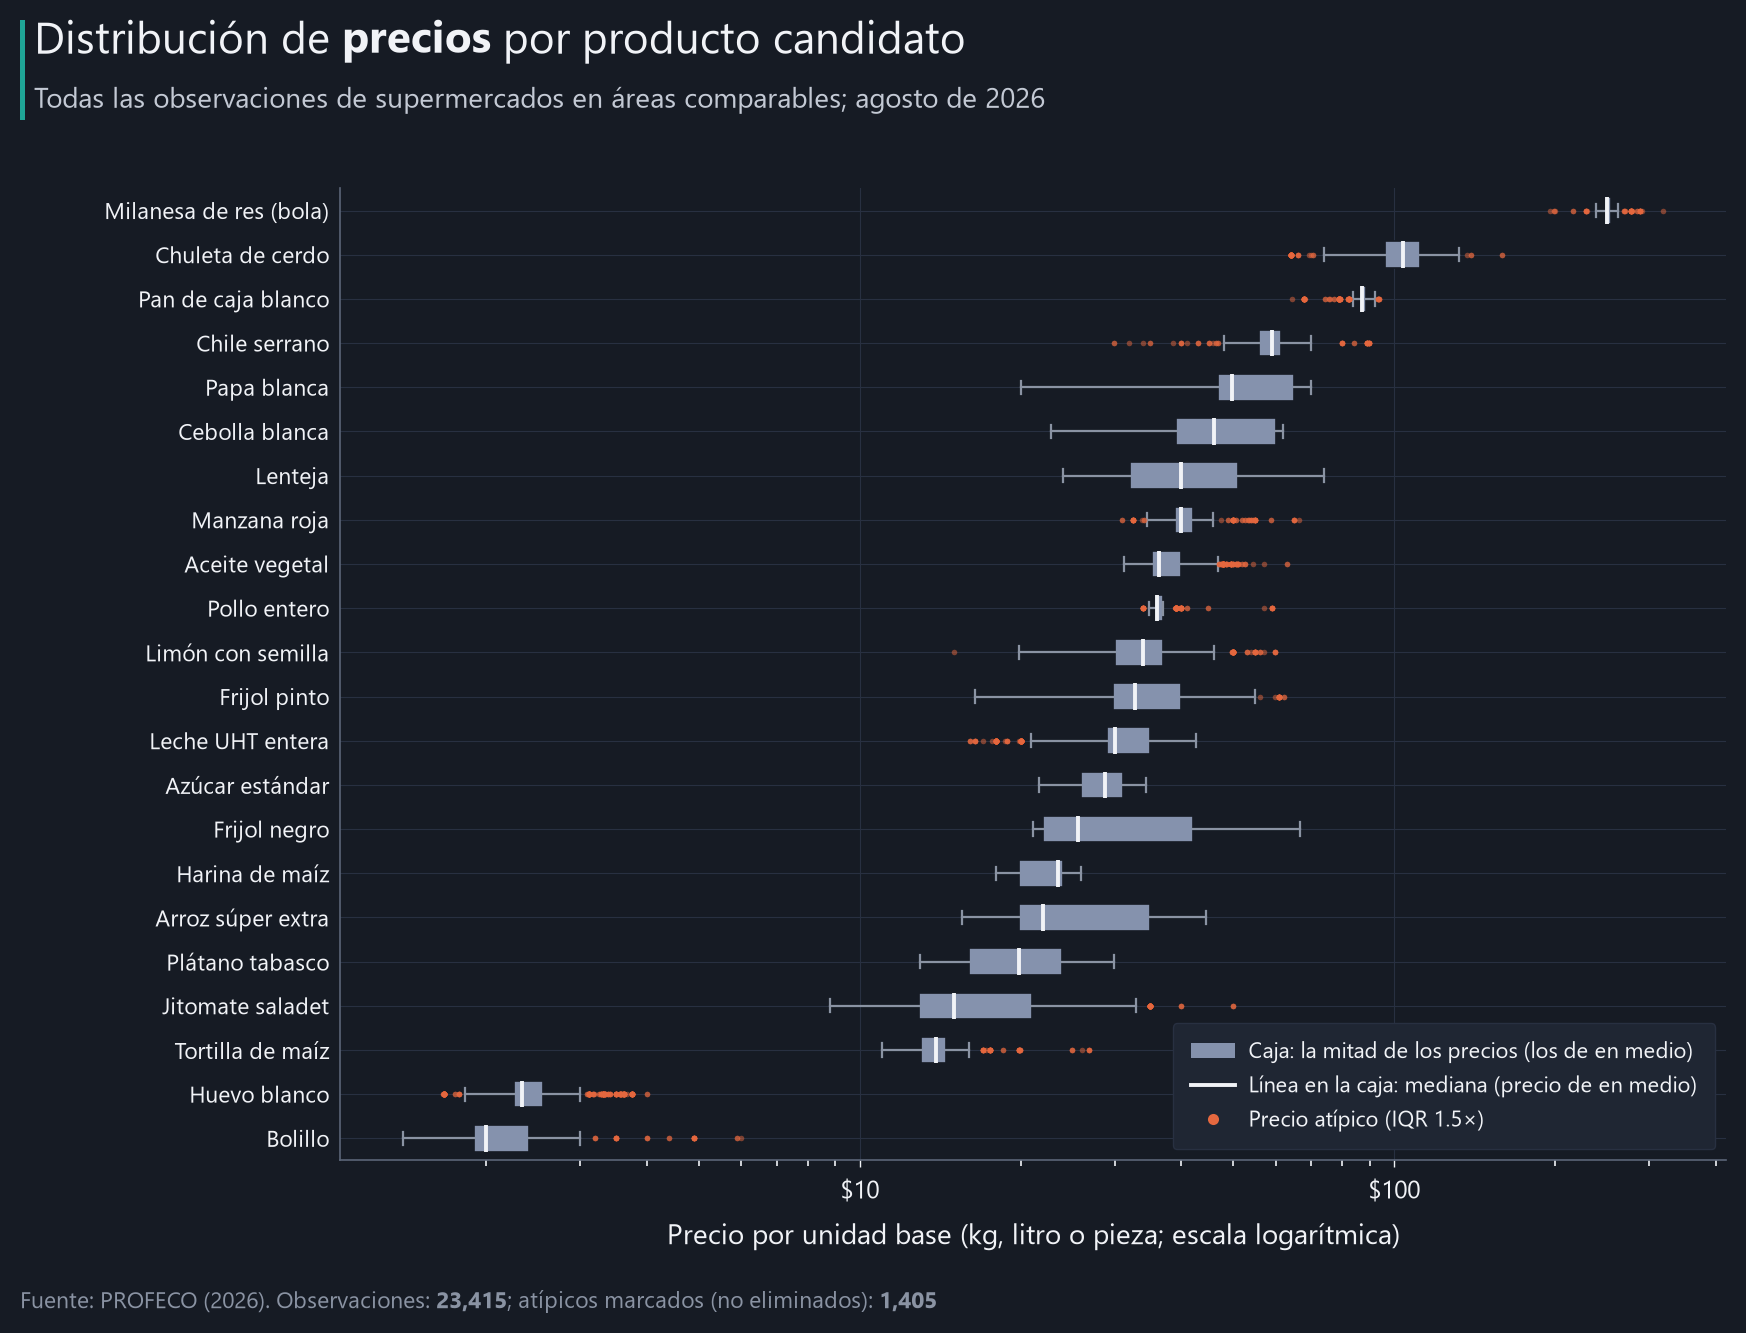

In [4]:
area_prices = area_item_prices(obs)
area_prices_sin_ext = area_item_prices(obs[~obs.extremo_iqr])
cmp = area_prices.merge(area_prices_sin_ext, on=["cd_ensu", "area_urbana_ensu", "producto_normalizado"],
                        suffixes=("", "_sin_extremos"))
cmp["dif_mediana_pct"] = (cmp.precio_mediana_sin_extremos / cmp.precio_mediana - 1) * 100
cmp["dif_media_vs_mediana_pct"] = (cmp.precio_media / cmp.precio_mediana - 1) * 100
display(cmp[["dif_mediana_pct", "dif_media_vs_mediana_pct"]].describe().round(2))
ext = obs[obs.extremo_iqr].groupby("producto_normalizado").agg(
    extremos=("precio_unitario", "size"), minimo=("precio_unitario", "min"), maximo=("precio_unitario", "max"))
display(ext.round(2))
from src import charts
charts.price_boxplot(obs, names, ROOT / "outputs/charts/00b_distribucion_precios.png")
plt.show()

## 3. Cobertura producto × área y mínimo de establecimientos

Una mediana de uno o dos supermercados es frágil. Se observa la distribución de
establecimientos de autoservicio por área antes de fijar un mínimo.

In [5]:
stores = obs.groupby("area_urbana_ensu").agg(establecimientos=("establecimiento_id", "nunique"),
                                              observaciones=("precio_unitario", "size"))
display(stores.establecimientos.value_counts().sort_index().to_frame("áreas"))
n_areas = homolog.loc[homolog.incluir, "cd_ensu"].nunique()
sin_autoservicio = sorted(set(homolog.loc[homolog.incluir, "area_urbana_ensu"]) - set(stores.index))
print("Áreas comparables sin supermercados PROFECO:", sin_autoservicio)
MIN_ESTABLECIMIENTOS = 3
eligible = sorted(stores[stores.establecimientos >= MIN_ESTABLECIMIENTOS].index)
print(f"Con ≥{MIN_ESTABLECIMIENTOS} establecimientos: {len(eligible)} de {len(stores)} áreas con autoservicio")
matrix, cov = coverage_matrix(area_prices, n_areas)
display(cov.assign(nombre=names).round(1))

,áreas
establecimientos,
1,2
2,5
4,4
5,18
6,11
7,2
8,2
9,4
10,3


Áreas comparables sin supermercados PROFECO: ['General Escobedo', 'Guadalupe', 'San Pedro Tlaquepaque']
Con ≥3 establecimientos: 45 de 52 áreas con autoservicio


,areas_con_precio,cobertura_pct,nombre
producto_normalizado,,,
aceite,52,94.5,Aceite vegetal
arroz,52,94.5,Arroz súper extra
azucar,52,94.5,Azúcar estándar
jitomate,52,94.5,Jitomate saladet
leche_entera,52,94.5,Leche UHT entera
frijol_negro,52,94.5,Frijol negro
papa,52,94.5,Papa blanca
platano,52,94.5,Plátano tabasco
manzana,52,94.5,Manzana roja


## 4. Selección de productos

Se parte de los 22 candidatos de consumo común y se exige **composición completa**: un área
sin un producto no recibe costo. Comparar sumas con productos faltantes abarataría
artificialmente a esas ciudades.

Regla iterativa: si un producto es el único faltante en una o más áreas elegibles, se
retira el que excluye más áreas. Se repite hasta que ningún producto, por sí solo, deje
fuera un área.

In [6]:
items, log, complete = select_items(area_prices, eligible)
display(log)
print(f"Canasta final: {len(items)} productos; áreas elegibles con composición completa: {complete.sum()} de {len(eligible)}")
display(complete[~complete])

,producto_retirado,areas_recuperadas,areas
0,bolillo,2,"Cuernavaca, Culiacán Rosales"


Canasta final: 21 productos; áreas elegibles con composición completa: 45 de 45


Series([], dtype: bool)

## 5. Marcas: opción A vs. opción B

- **A:** producto + presentación equivalente con cualquier marca y precio mediano.
- **B:** misma marca en todas las áreas (para cada producto, la marca presente en más áreas).

B controla la composición de marcas, pero pierde las áreas donde esa marca no se observó.
Se comparan cobertura y ordenamiento.

,producto_normalizado,marca,areas
0,aceite,1_2_3,51
1,arroz,Schettino,51
2,azucar,Zulka,51
3,cebolla,S/M,51
4,cerdo_chuleta,S/M,51
5,chile_serrano,S/M,51
6,frijol_negro,Verde Valle,50
7,frijol_pinto,Verde Valle,50
8,harina_maiz,Maseca,51
9,huevo_blanco,Bachoco,52


,áreas con costo
A_mediana,45
A_media,45
B_misma_marca,42


,A_mediana,A_media,B_misma_marca
A_mediana,1.000,0.806,0.827
A_media,0.806,1.000,0.660
B_misma_marca,0.827,0.660,1.000


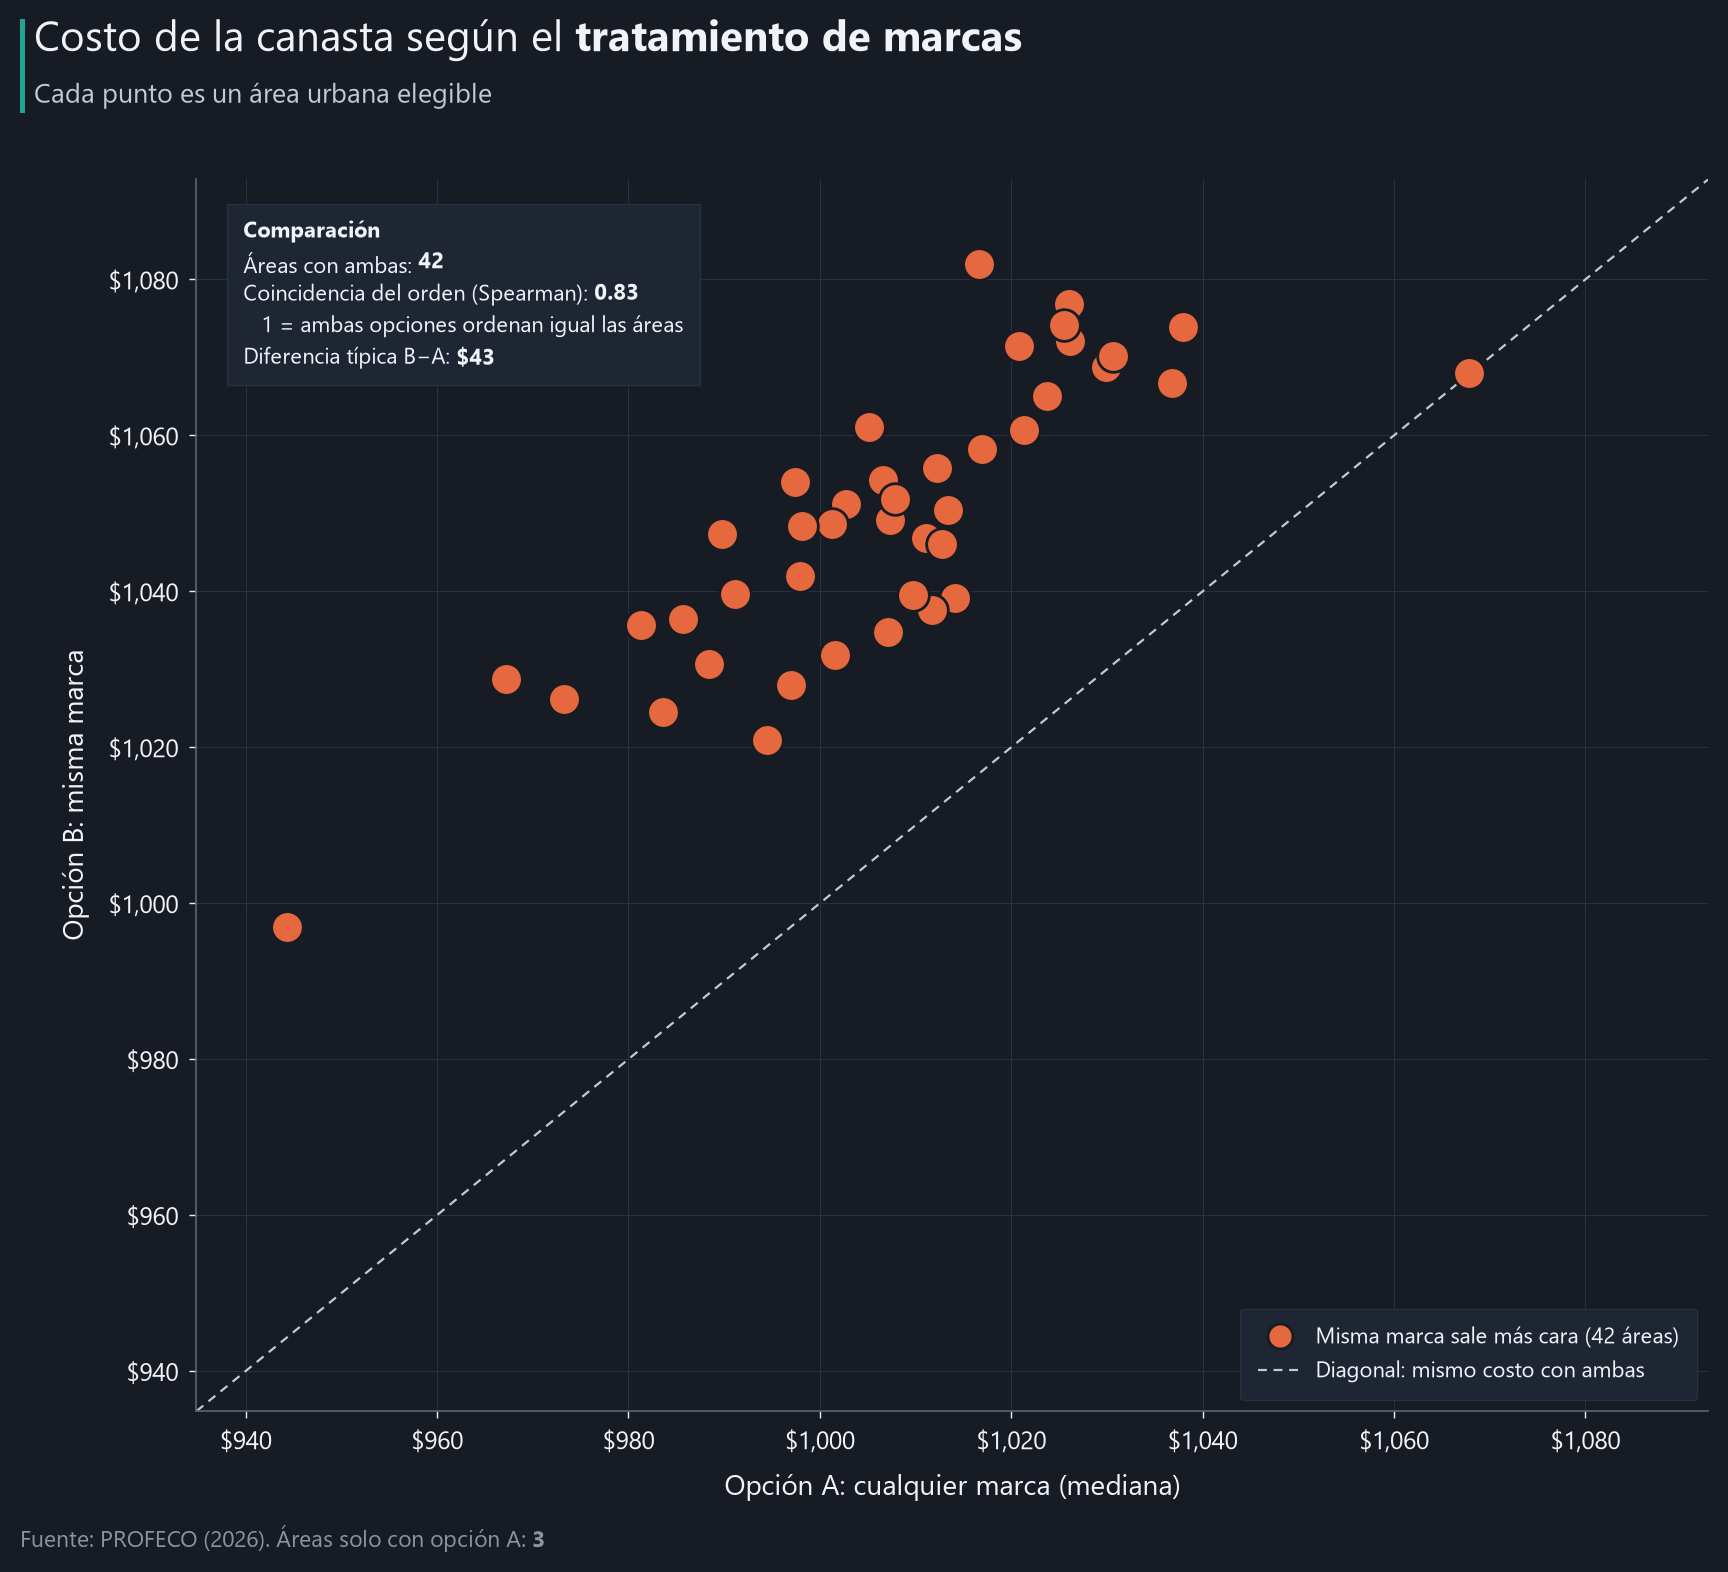

In [7]:
picked, chosen = brand_option(obs, items)
display(chosen)
A = basket_cost(area_prices, items).set_index("area_urbana_ensu").costo_canasta
Amedia = basket_cost(area_prices, items, "precio_media").set_index("area_urbana_ensu").costo_canasta
B = basket_cost(picked, items).set_index("area_urbana_ensu").costo_canasta
metodos = pd.DataFrame({"A_mediana": A, "A_media": Amedia, "B_misma_marca": B}).loc[eligible]
display(metodos.notna().sum().to_frame("áreas con costo"))
display(metodos.corr(method="spearman").round(3))
charts.methods_scatter(metodos, ROOT / "outputs/charts/00c_metodos_marca.png")
plt.show()

**Decisión:** opción A con mediana. Ordena las áreas de forma parecida a B
(correlación de Spearman mostrada arriba), conserva más áreas y la mediana entre
establecimientos limita el efecto de marcas premium aisladas. B y la media se conservan
como pruebas de sensibilidad en el notebook 04.

In [8]:
definicion = CANDIDATOS.copy()
definicion["presentaciones"] = definicion.presentaciones.str.join(" | ")
definicion["incluido"] = definicion.producto_normalizado.isin(items)
definicion["motivo"] = np.where(definicion.incluido, "Cobertura completa en áreas elegibles",
    "Retirado: único faltante en " + definicion.producto_normalizado.map(log.set_index("producto_retirado").areas).fillna(""))
definicion = definicion.merge(cov, left_on="producto_normalizado", right_index=True)
definicion.to_csv(PROC / "canasta_definicion.csv", index=False, encoding="utf-8-sig")
area_prices.to_csv(PROC / "precios_area_producto.csv", index=False, encoding="utf-8-sig")
matrix.T.to_csv(PROC / "cobertura_canasta_matriz.csv", encoding="utf-8-sig")
metodos.reset_index().to_csv(PROC / "comparacion_metodos_canasta.csv", index=False, encoding="utf-8-sig")
log.to_csv(PROC / "seleccion_productos_bitacora.csv", index=False, encoding="utf-8-sig")
keep = ["cd_ensu", "area_urbana_ensu", "estado", "municipio", "establecimiento_id", "cadena_comercial",
        "producto_normalizado", "producto", "presentacion", "marca", "precio_num", "cantidad_presentacion",
        "unidad", "precio_unitario", "fecha", "lat", "lon", "extremo_iqr"]
obs[keep].to_csv(PROC / "observaciones_canasta.csv", index=False, encoding="utf-8-sig")
(ROOT / "data/metadata/canasta_parametros.json").write_text(json.dumps({
    "canal": CANAL, "min_establecimientos": MIN_ESTABLECIMIENTOS, "productos": items,
    "fecha_inicio": str(obs.fecha.min().date()), "fecha_fin": str(obs.fecha.max().date()),
    "metodo": "Opción A: mediana por establecimiento y mediana entre establecimientos",
}, ensure_ascii=False, indent=2), encoding="utf-8")
display(Markdown(f"**Canasta:** {len(items)} productos: " + ", ".join(names[i] for i in items) + "."))

**Canasta:** 21 productos: Tortilla de maíz, Huevo blanco, Leche UHT entera, Frijol negro, Frijol pinto, Arroz súper extra, Azúcar estándar, Aceite vegetal, Harina de maíz, Lenteja, Jitomate saladet, Cebolla blanca, Papa blanca, Chile serrano, Plátano tabasco, Manzana roja, Limón con semilla, Pollo entero, Milanesa de res (bola), Chuleta de cerdo, Pan de caja blanco.